# Candidate evidence in a baseline vaccination repertoire

How does LLWNGPMAV candidate evidence relate to clone abundance? Follow one real baseline TRB repertoire from raw counts to annotation and read-weighted plots. Ordinary annotation retains exact reference evidence.

**Before you start**

Install `vdjmatch[bench,notebook]` and `ipykernel`. Open from the repository root or the complete `examples` directory. The default mirrors are `~/hf/airr_yfv19` and `~/hf/airr_benchmark`; override them with `AIRR_YFV19` and `AIRR_BENCHMARK`. Set `YFV_INPUT` to choose a specific baseline table. Original sample identifiers remain private.

## 1. Environment and scope

Use the 10,000 most abundant unique V/junction/J clonotypes from one complete baseline table. This deterministic subset is abundance-enriched, so report its read-count coverage against all eligible TRB rows. Four native workers process one batch.

In [ ]:
# Set budgets before numerical imports; every calculation uses a fresh CLI output directory.
import os, sys, json, tempfile, platform, subprocess, hashlib
from pathlib import Path
from importlib.metadata import version
THREADS = 4
for key in ("POLARS_MAX_THREADS", "OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir())/"vdjmatch-matplotlib"))
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import psutil
examples = next(p for p in (Path.cwd()/"examples", Path.cwd()) if (p/"profile_cli.py").is_file())
sys.path.insert(0, str(examples))
from profile_cli import profile
output = Path(tempfile.mkdtemp(prefix="vdjmatch-scientific-example-"))
benchmark = Path(os.environ.get("AIRR_BENCHMARK", Path.home()/"hf/airr_benchmark"))
reference = benchmark/"vdjdb/vdjdb-2026-06-11-ZENODO/vdjdb_full.txt.gz"
if not reference.is_file():
    raise FileNotFoundError("Set AIRR_BENCHMARK to the complete local benchmark mirror")
print("Python", platform.python_version(), platform.machine())
for package in ("vdjmatch", "vdjtools", "seqtree", "polars", "matplotlib", "scikit-learn", "psutil"):
    print(package, version(package))
print("Logical CPUs:", psutil.cpu_count(), "physical cores:", psutil.cpu_count(logical=False),
      "RAM (GB):", round(psutil.virtual_memory().total/1e9, 1))
print("Fresh output directory:", output)
print("Reference SHA256:", hashlib.sha256(reference.read_bytes()).hexdigest())
# Consistent final-size typography and colour-blind-safe scientific encodings.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":8, "axes.labelsize":8,
                    "axes.titlesize":9, "legend.fontsize":7, "xtick.labelsize":7,
                    "ytick.labelsize":7, "axes.spines.top":False, "axes.spines.right":False,
                    "pdf.fonttype":42, "svg.fonttype":"none", "figure.dpi":150})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
def export(fig, name):
    for extension in ("pdf", "svg", "png"):
        fig.savefig(output/f"{name}.{extension}", dpi=300, bbox_inches="tight")


## 2. Load and select clonotypes

Sum `duplicate_count` within each supplied V/junction/J key; keep different J calls distinct. Retain anchor-inclusive junctions. Count non-TRB rows, invalid junctions and absent V calls before exclusion. Abundance here means read counts, not cells.

In [ ]:
# Load privately, collapse identical amino-acid V/junction/J keys, and report retained denominators.
yfv=Path(os.environ.get("AIRR_YFV19",Path.home()/"hf/airr_yfv19"))
source=Path(os.environ["YFV_INPUT"]) if "YFV_INPUT" in os.environ else sorted(yfv.glob("*.airr.tsv.gz"))[0]
source_digest=hashlib.sha256(source.read_bytes()).hexdigest()
raw_yfv=pl.read_csv(source,separator="\t")
v_col="v_call" if "v_call" in raw_yfv.columns else "v_gene"
j_col="j_call" if "j_call" in raw_yfv.columns else "j_gene"
eligible=raw_yfv.filter((pl.col("locus")=="TRB") &
    pl.col("junction_aa").str.contains(r"^C[ACDEFGHIKLMNPQRSTVWY]+[FW]$") &
    pl.col(v_col).is_not_null() & (pl.col(v_col)!=""))
clones=(eligible.group_by(v_col,"junction_aa",j_col).agg(pl.col("duplicate_count").sum())
    .rename({v_col:"v_call",j_col:"j_call"})
    .sort(["duplicate_count","v_call","junction_aa","j_call"],descending=[True,False,False,False]))
COUNT=10_000
queries=clones.head(COUNT).with_row_index("sequence_id").with_columns(pl.lit("TRB").alias("locus"))
all_reads=int(eligible["duplicate_count"].sum());retained_reads=int(queries["duplicate_count"].sum())
print("Raw rows:",raw_yfv.height,"eligible rows:",eligible.height,"dropped rows:",raw_yfv.height-eligible.height)
print("Unique eligible clonotypes:",clones.height,"selected:",queries.height)
print("Retained read counts:",retained_reads,"/",all_reads,"fraction:",retained_reads/all_reads)
queries.write_csv(output/"baseline.tsv",separator="\t")
# Source digest is private provenance; filenames and donor labels are not displayed.
(output/"private-source.json").write_text(json.dumps({"sha256":source_digest,"selected_clonotypes":queries.height}))
del raw_yfv,eligible


Raw rows: 624081 eligible rows: 592756 dropped rows: 31325
Unique eligible clonotypes: 578812 selected: 10000
Retained read counts: 124390 / 833386 fraction: 0.14925856685857453


## 3. Annotate LLWNGPMAV

The CLI keeps each VDJdb MHC restriction for the peptide; no donor HLA genotype is assumed. `--details` exports full-pMHC evidence. Exact reference support is retained, as in ordinary annotation.

In [ ]:
# Run a fresh targeted annotation and measure its complete CLI process tree.
command=[sys.executable,"-m","vdjmatch.cli","annotate",str(output/"baseline.tsv"),
         "--vdjdb",str(reference),"--locus","TRB","--epitope","LLWNGPMAV",
         "--details","--threads",str(THREADS),"--output-prefix",str(output/"llw")]
usage=profile(command,output/"llw.log",timeout=300)
print({k:round(v,3) if isinstance(v,float) else v for k,v in usage.items()})


## 4. Join evidence to abundance

Keep every selected clonotype. For the plots, take the maximum score across LLW MHC restrictions and label that aggregation explicitly. No-support rows remain in the table and read-count denominator.

In [ ]:
# Join source identities and aggregate only for a clearly labelled descriptive display.
evidence=pl.read_csv(output/"llw.enrichment.tsv",separator="\t")
PMHC=["epitope","mhc_a","mhc_b","mhc_class"]
print(evidence.select(PMHC).unique().sort(PMHC))
per_clone=evidence.group_by("source_sequence_id").agg(pl.col("kernel_score").max().alias("score"))
view=queries.with_columns(pl.col("sequence_id").cast(pl.String).alias("source_sequence_id"))
view=view.join(per_clone.with_columns(pl.col("source_sequence_id").cast(pl.String)),
               on="source_sequence_id",how="left",validate="1:1")
assert view.height==queries.height
view=view.with_columns((pl.col("duplicate_count")/all_reads).alias("read_fraction"))
print("Missing score:",view["score"].null_count(),"of",view.height,"selected clonotypes")


## 5. Plot abundance and coverage

Ranked abundance shows repertoire concentration. Cumulative coverage uses all eligible TRB read counts as its denominator, so the endpoint reports the selected subset's coverage.

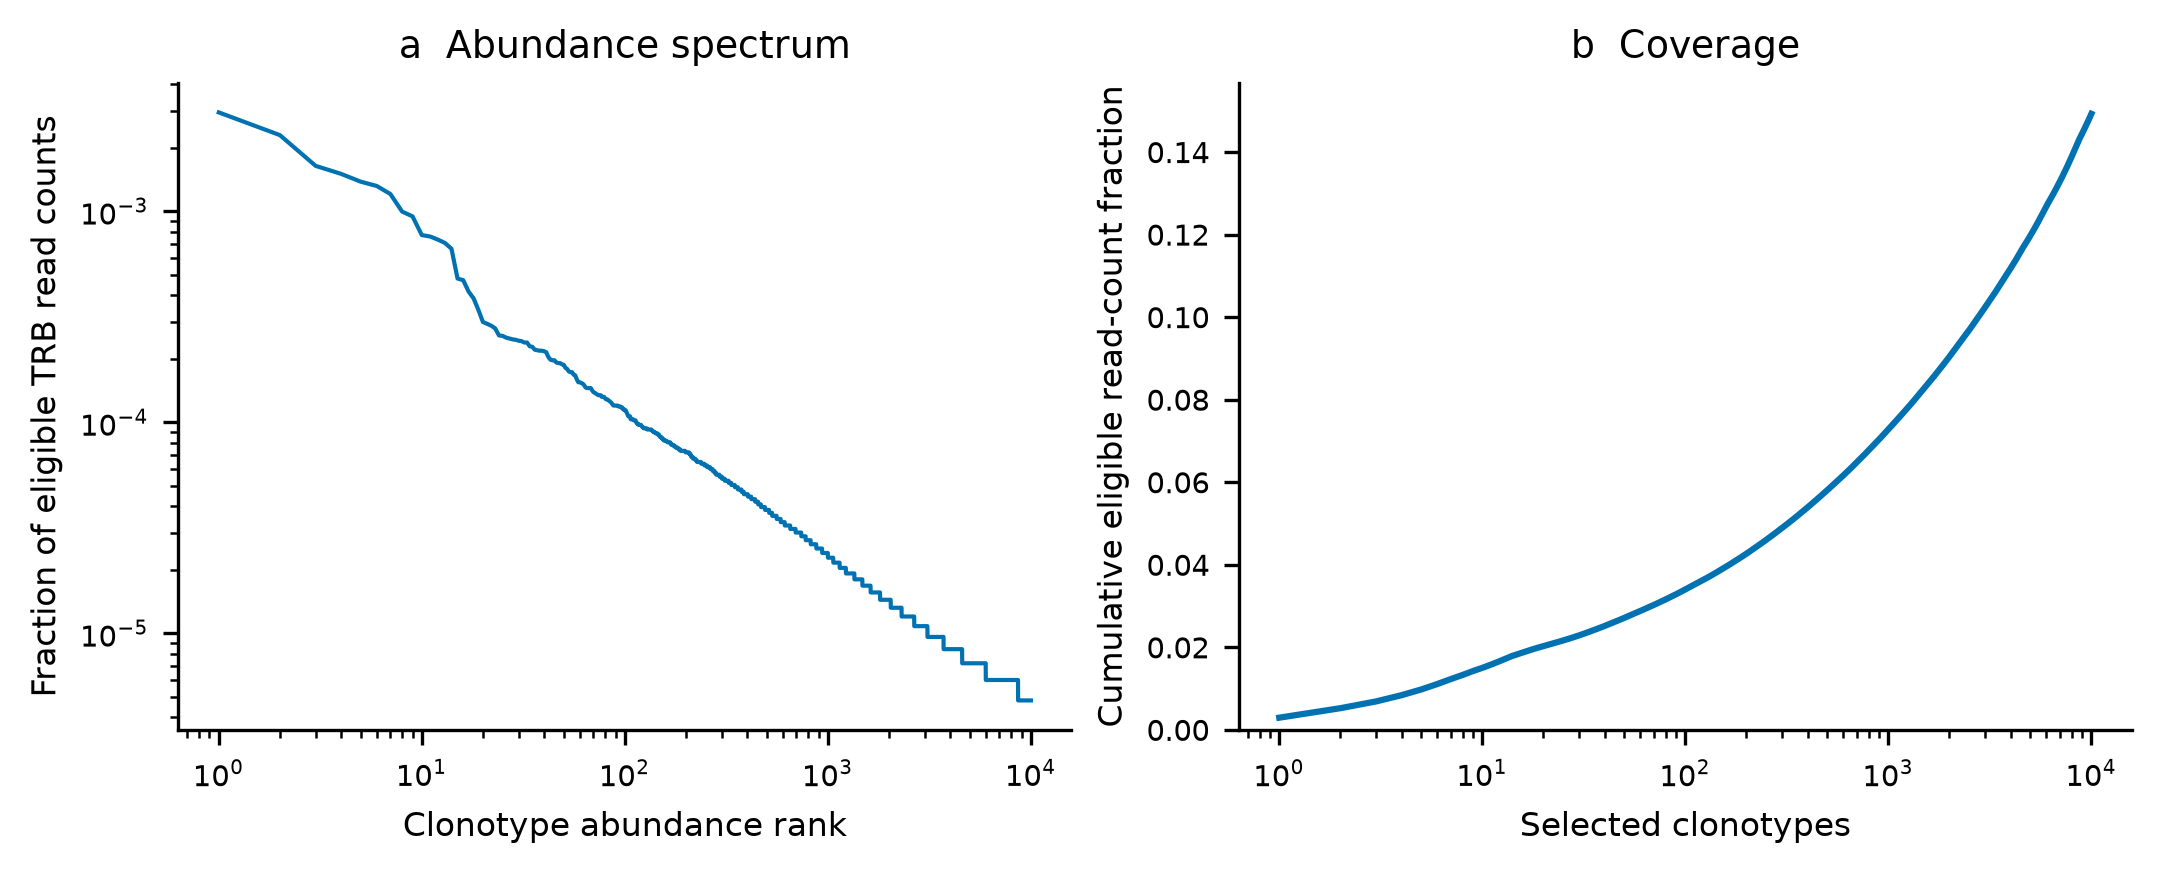

In [ ]:
# Show repertoire concentration and the full-denominator coverage of the selected subset.
rank=np.arange(1,view.height+1)
fig,axes=plt.subplots(1,2,figsize=(7.09,2.8),layout="constrained")
axes[0].plot(rank,view["read_fraction"].to_numpy(),color="#0072B2",lw=1)
axes[0].set(xscale="log",yscale="log",xlabel="Clonotype abundance rank",ylabel="Fraction of eligible TRB read counts",title="a  Abundance spectrum")
axes[1].plot(rank,np.cumsum(view["read_fraction"].to_numpy()),color="#0072B2",lw=1.5)
axes[1].set(xscale="log",xlabel="Selected clonotypes",ylabel="Cumulative eligible read-count fraction",ylim=(0,retained_reads/all_reads*1.05),title="b  Coverage")
export(fig,"baseline-abundance");plt.show()


**Figure 1 | Abundance and coverage of selected baseline TRB clonotypes.** **a**, Read-count fraction by descending abundance rank on logarithmic axes. **b**, Cumulative fraction of all eligible TRB read counts represented by the selected clonotypes. Each clonotype is a distinct supplied V/junction/J combination; duplicate counts are summed. Neither panel measures a cell count or antigen binding.

## 6. Plot evidence against abundance

Each point links a clonotype's relative LLW evidence to its read-count fraction. The adjacent curve weights scores by read counts, showing where observed abundance lies on the evidence scale.

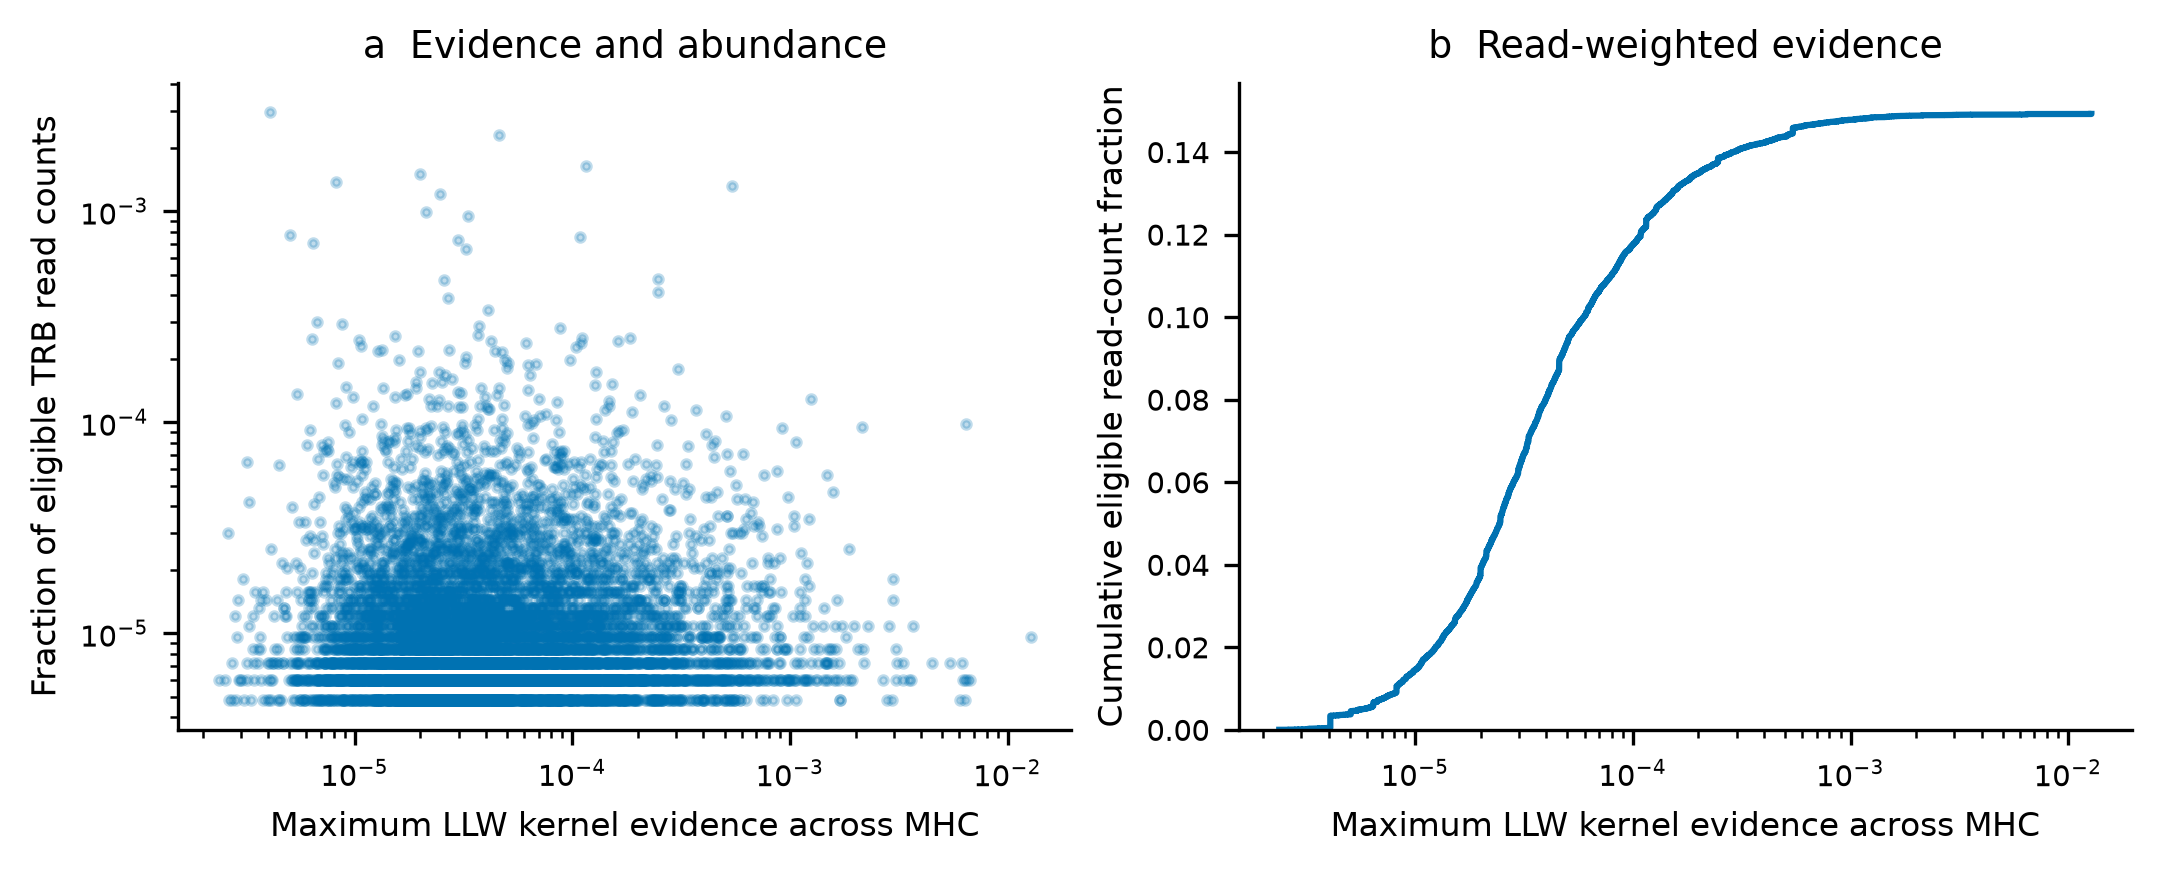

In [ ]:
# Draw relative LLW evidence against abundance and a read-weighted cumulative evidence distribution.
valid=view.filter(pl.col("score").is_finite()).sort("score")
fig,axes=plt.subplots(1,2,figsize=(7.09,2.8),layout="constrained")
axes[0].scatter(valid["score"],valid["read_fraction"],s=4,alpha=.25,color="#0072B2",rasterized=True)
axes[0].set(xscale="log",yscale="log",xlabel="Maximum LLW kernel evidence across MHC",ylabel="Fraction of eligible TRB read counts",title="a  Evidence and abundance")
axes[1].step(valid["score"],np.cumsum(valid["duplicate_count"].to_numpy())/all_reads,
             where="post",color="#0072B2",lw=1.5)
axes[1].set(xscale="log",xlabel="Maximum LLW kernel evidence across MHC",ylabel="Cumulative eligible read-count fraction",ylim=(0,retained_reads/all_reads*1.05),title="b  Read-weighted evidence")
export(fig,"baseline-evidence");plt.show()


**Figure 2 | Relative LLW candidate evidence and baseline clone abundance.** **a**, Each point is a selected TRB clonotype with finite evidence; the vertical axis is its fraction of all eligible read counts. **b**, Read-count-weighted cumulative distribution of finite scores, with the same complete-table denominator. Scores are the maximum across the full MHC restrictions for LLWNGPMAV, used only for this descriptive visualisation. Unsupported clonotypes remain in the source/output tables and denominators.

## 7. Export counts and resource measurements

In [ ]:
# Export descriptive denominators without publishing original sample names or sequence identifiers.
pl.DataFrame([{"eligible_clonotypes":clones.height,"selected_clonotypes":queries.height,
               "eligible_read_counts":all_reads,"retained_read_counts":retained_reads,
               "retained_read_fraction":retained_reads/all_reads}]).write_csv(output/"coverage.tsv",separator="\t")
pl.DataFrame([{"workflow":"Baseline targeted TRB","queries":queries.height,"native_threads":THREADS,**usage}]).write_csv(output/"resources.tsv",separator="\t")


## Interpretation and limits

The plots connect relative LLW support to observed baseline abundance.

- The top-abundance subset is biased towards expanded clones; it cannot estimate full-repertoire specificity prevalence.
- Maximum evidence across MHC is a descriptive score. Donor restriction is unknown, and no binding labels or calibrated call threshold are supplied.
- Baseline data cannot establish vaccine-induced expansion; that requires paired time points and replicate identities.
- Read-count abundance, cell counts and model precursor frequency are different quantities.

Keep raw rows, sample names, provenance mappings and detailed source-identifiable tables private. The aggregate plots expose none of those identifiers.